# Numerical Analysis
## Lab 2 - Numerical methods for nonlinear zeros
*M. Fois  A.Y. 2026/2027*

### Setup
Run this cell first: it selects a graphics toolkit that can draw inside the notebook (without it, plots fail with the `DISPLAY=''` error).

In [1]:
warning("off", "Octave:gnuplot-graphics");
graphics_toolkit("gnuplot");
%plot inline











The FLTK graphics toolkit is not actively maintained and has a number
of limitations that are unlikely to be fixed.
The qt toolkit is recommended instead.








---
### Exercise 2.1
Write a function that implements the **Bisection Method** for finding the zeros of nonlinear functions.

The method halves at each step an interval $[a,b]$ with $f(a) f(b) < 0$, so the number of iterations needed to reach a tolerance $\tau$ is known in advance:

$$k_{\min} = \left\lceil \frac{\log\!\left(\frac{b-a}{\tau}\right)}{\log 2} \right\rceil.$$

> Run this cell once: it defines the function used by Exercises 2.2 and 2.3.

In [12]:
function [ c, iterations ] = bisection( f, a, b, tol, maxit )
    expected_iterations = ceil((log((b-a)/tol))/log(2));
    fprintf('Expected number of iterations = %d\n', expected_iterations);
    fa = feval(f, a);
    fb = feval(f, b);
    if sign(fa)*sign(fb) >= 0
        error('There are no zeros inside this interval');
    else
        iterations = 0;
        
        while (b - a) > tol && iterations <= maxit
            iterations = iterations + 1;
            c = a + (b - a)/2; # We do this instead of (a + b)/2 to avoid overflow
            fc = feval(f, c);
            if fc == 0
                return;
            end
            if c == a || c == b
                error('The interval is below the machine precision');
            end
            if sign(fc) * sign(fa) > 0
                a = c;
            else
                b = c;
            end
        end 
    end
end

---
### Exercise 2.2
Write a script that approximates $\sqrt{3}$ with an error smaller than $10^{-5}$, using the Bisection Method. Consider the interval $[0, 4]$. How many iterations are needed to achieve the required tolerance?

The zero of $f(x) = x^2 - 3$ in $[0,4]$ is exactly $\sqrt{3}$, and $f(0) f(4) < 0$, so the method can be applied.

In [13]:
% Ex 2.2 - Approximation of sqrt(3)
clear; close all

f = @(x) x.^2 - 3;

a = 0;
b = 4;
tol = 1e-5;
maxit = 100;

[xvect, it] = bisection(f, a, b, tol, maxit);

it
xvect
err = abs(sqrt(3) - xvect) / sqrt(3)












Expected number of iterations = 19


it = 19

xvect = 1.7320

err = 1.6009e-06


**Comment.** The a priori estimate gives

$$k_{\min} = \left\lceil \frac{\log(4/10^{-5})}{\log 2} \right\rceil = 19,$$

and the loop indeed stops after $19$ iterations: the bisection method does not depend on the shape of $f$, only on the length of the starting interval.

---
### Exercise 2.3
It is known that the function $g(x) = \arctan(x-1)$ admits as its unique zero in any interval of the type $[-1, \delta]$, $\delta > 1$, the point $x = 1$. Approximate this zero with the Bisection Method, setting $\delta = 1.5$, maximum number of iterations $n_{\max} = 200$, and stopping criterion based on the iterations

$$|x_{k+1} - x_k| < \tau,$$

where $\tau = 10^{-8}$ is the tolerance.

In [15]:
% Ex 2.3
clear; close all

f  = @(x) atan(x - 1);
df = @(x) 1./(1 + (x-1).^2);

x_es = 1;      % exact zero

[xvect, it] = bisection(f, -1, 1.5, 1e-8, 200);
it
xvect
err = abs(1 - xvect)










Expected number of iterations = 28

it = 28

xvect = 1.0000

err = 1.8626e-09


---
### Exercise 2.4
The **Newton-Raphson Method** is a numerical method with quadratic convergence, but it is local: such an order of convergence is guaranteed only provided that $f \in C^2$ and that $f'(\alpha) \neq 0$, with $\alpha$ such that $f(\alpha) = 0$.

Write a function that implements the method, with stopping criterion based on the maximum number of iterations $n_{\max}$ and

$$|x_{k+1} - x_k| < \tau .$$

Test the code with

$$f(x) = 1 - x^3 - 2x \sin(2x), \qquad f'(x) = -3x^2 - 2\sin(2x) - 4x\cos(2x),$$

in the interval $[0.3, 0.8]$, with initial guess $x_0 = 0.6$, $n_{\max} = 20$ and $\tau = 10^{-8}$. Verify numerically the quadratic convergence of the method.

*Hint: build a vector containing the difference between successive iterates and plot it as a function of the number of iterations in a semilogarithmic scale.*

In [24]:
function [ xvect, it, dif ] = newton(x0, nmax, tol, f, df)
    it = 0;
    err = tol + 1;
    xold = x0;
    dif = [];
    xvect = x0;
    
    while it < nmax && err > tol
        it = it + 1;
        xnew = xold - f(xold)/df(xold);
        err = abs(xnew - xold);
        dif = [dif err];
        xvect = [xvect xnew];
    end
end

In [26]:
% Ex 2.4 - Newton-Raphson method
clear; close all

f  = @(x) 1 - x.^3 - 2*x.*sin(2.*x);
df = @(x) -3.*x.^2 - 2.*sin(2.*x) - 4.*x.*cos(2.*x);
x = linspace(0, 1, 30);

newton(x, 20, 1e-8, f, df);





error: invalid use of 'end': may only be used to index existing value






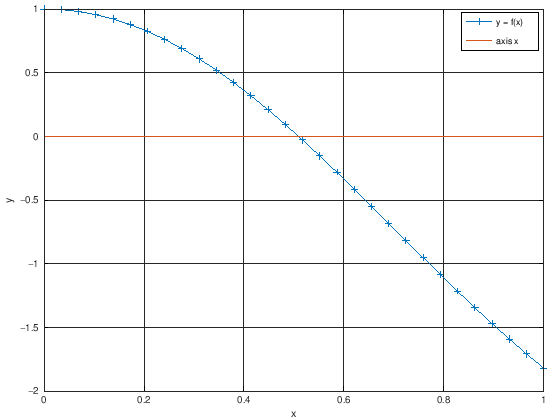

In [27]:
figure()
plot(x, f(x), '+-', x, zeros(size(x)));
hold on
scatter(xvect(end), 0, 20, 'r', 'filled')
grid on
xlabel('x')
ylabel('y')
legend('y = f(x)', 'axis x')



error: 'it' undefined near line 1, column 12





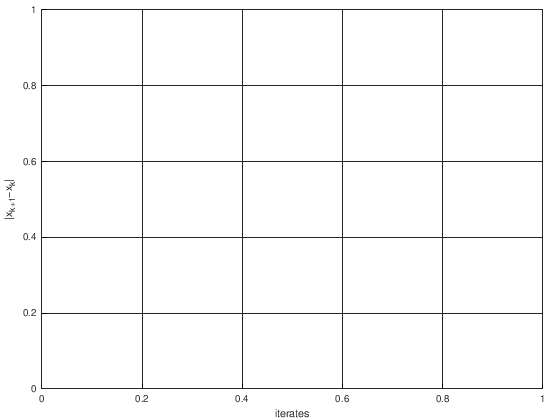

In [28]:
figure()
semilogy(1:it, xdiff, '-x');
grid on
xlabel('iterates');
ylabel('|x_{k+1}-x_{k}|')

**Comment.** In the semilogarithmic plot the increments do not decrease along a straight line, as they would for a linearly convergent method: the slope becomes steeper at every step, because the number of correct digits roughly doubles at each iteration. This is the signature of **quadratic convergence**,

$$|x_{k+1} - \alpha| \le C\, |x_k - \alpha|^2 .$$

---
### Exercise 2.5
The function $f(x) = \log x + \frac{1}{4}x^2 - \frac{1}{4}$ is continuous on $\mathbb{R}^+$ and admits a unique zero at $x = 1$. A researcher is trying to approximate this zero with a fixed-point method, but is undecided about which $\phi(x)$ to use as the iteration function. The possible choices are

$$\phi_1(x) = \frac{1}{3}\left(\log x + \frac{1}{4}x^2 - \frac{1}{4}\right), \qquad
\phi_2(x) = \left(1 - \frac{1}{4}x\right)x - \log x + \frac{1}{4}, \qquad
\phi_3(x) = x + e^{\frac{1}{4}x^2 - \frac{1}{4}} .$$

Only one of them guarantees the convergence of the method. How did the researcher identify the correct $\phi(x)$? Which one of the three is it?

Once the correct $\phi(x)$ has been established, apply it to a fixed-point method with $\text{tol} = 10^{-6}$, $x_0 = 0.6$ and maximum number of iterations equal to $30$.

In [ ]:
function [xvect, it, err] = fixedpoint(x0, nmax, toll, phi)

incr  = toll + 1;
err   = [];
it    = 0;
xvect = x0;
xv    = x0;

while ....

end

end

In [ ]:
% Ex 2.5
clear; close all

f = @(x) log(x) + 1/4.*x.^2 - 1/4;

....

In [ ]:
% The three candidate iteration functions and their derivatives
phi1  = @(x) f(x)./3;
dphi1 = @(x) 1/3.*(1./x + 1/2.*x);

phi2  = @(x) x - f(x);
dphi2 = @(x) 1 - (1./x + 1/2.*x);

phi3  = @(x) x + exp(1/4.*x.^2 - 1/4);
dphi3 = @(x) 1 + (1/2.*x).*exp(1/4.*x.^2 - 1/4);

% Is x = 1 a fixed point? phi(1) must be equal to 1
[phi1(1) phi2(1) phi3(1)]

% Derivatives at the zero: |dphi(1)| < 1 is required for local convergence
[dphi1(1) dphi2(1) dphi3(1)]

**How to choose $\phi$.** A fixed-point iteration $x_{k+1} = \phi(x_k)$ can converge to $\alpha = 1$ only if two conditions hold:

1. $\alpha$ must be a **fixed point** of $\phi$, i.e. $\phi(1) = 1$;
2. the iteration must be **locally convergent**, i.e. $|\phi'(1)| < 1$.

Checking the candidates:

- $\phi_1(1) = \frac{1}{3} f(1) = 0 \neq 1$ — the zero of $f$ is not a fixed point of $\phi_1$, so the method cannot converge to it;
- $\phi_3(1) = 1 + e^{0} = 2 \neq 1$ — same problem;
- $\phi_2(x) = x - f(x)$ gives $\phi_2(1) = 1 - f(1) = 1$, and

$$\phi_2'(x) = 1 - f'(x) = 1 - \left(\frac{1}{x} + \frac{x}{2}\right), \qquad \phi_2'(1) = -\frac{1}{2},$$

so $|\phi_2'(1)| = 0.5 < 1$: the iteration converges, **linearly**, with asymptotic rate $1/2$.

The correct choice is therefore $\boldsymbol{\phi_2}$.

In [ ]:
x0   = 0.6;
nmax = 30;
toll = 1e-6;

[xvect, it, err] = fixedpoint(x0, nmax, toll, phi2);

In [ ]:
% Convergence history
figure()
semilogy(1:it, err, '-o'); grid on
xlabel('iterates'); ylabel('|x_{k+1}-x_{k}|')
title('Fixed point iteration with \phi_2')

**Comment.** The increments lie on a straight line in the semilogarithmic plot: the convergence is **linear**, and the slope corresponds to the factor $|\phi_2'(1)| = 1/2$ (one extra correct binary digit per iteration). Compare it with the plot of Exercise 2.4, where Newton's quadratic convergence bends the curve downwards.

In [1]:
% Salva prima il notebook (Ctrl+S)
system('..\.venv\Scripts\jupyter nbconvert --to pdf "Lab2_Nonlinear_Zeros_lecture.ipynb"');

[NbConvertApp] Converting notebook Lab2_Nonlinear_Zeros_lecture.ipynb to pdf
[NbConvertApp] Writing 39470 bytes to notebook.tex
[NbConvertApp] Building PDF
[NbConvertApp] Running xelatex 3 times: ['xelatex', 'notebook.tex', '-quiet']
[NbConvertApp] Running bibtex 1 time: ['bibtex', 'notebook']
[NbConvertApp] WARNING | b had problems, most likely because there were no citations
[NbConvertApp] PDF successfully created
[NbConvertApp] Writing 71483 bytes to Lab2_Nonlinear_Zeros_lecture.pdf
